# 1x2 MMI Splitter — FDTD

Simulate a 1x2 MMI splitter with the FECES library using FDTD.

**Geometry:**
- Single-mode input waveguide -> MMI body -> two output waveguides
- SOI platform: 160 nm Si on SiO2
- Dimensions from typical fabricated device (mm_length = 4.5 um)

**Method:** FDTD via meep with GDS prism geometry and EigenModeSource. The full device is
simulated in a single domain. A multimode cross-section monitor is placed near the output
to capture coupling into all guided modes. Transmission to the dominant output mode
(mode 1) gives the port IL.

For the fastest result, use EME (`mmi_1x2_eme`). FDTD is the reference for validation and
for devices where EME is inaccurate (high-contrast bends, scattering geometries).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from feces import MMI, FDTDSolver, SOI_160, plot_fdtd_geometry

In [2]:
# Global simulation parameters
RESOLUTION = 40.0   # mesh resolution (pixels/um) — used by the FDTD solver
WL_MIN = 1.26       # wavelength sweep start (um)
WL_MAX = 1.36       # wavelength sweep end (um)
N_WL = 11           # number of wavelength points

In [3]:
# 1. Define geometry
mmi = MMI(
    n_inputs=1,             # 1x2 splitter
    n_outputs=2,
    mm_length=4.5,          # MMI body length (um)
    mm_width=2.0,           # MMI body width (um)
    waveguide_width=0.35,   # single-mode access waveguide width (um)
    taper_length=1.0,       # input/output taper length (um)
    taper_width=0.8,        # taper width at MMI junction (um)
    waveguide_offset=1.0,   # center-to-center output spacing (um)
    waveguide_height=0.16,  # Si layer thickness (um) — SOI_160
)

print(f"MMI total length: {mmi.total_length:.2f} um")

MMI total length: 6.50 um


In [4]:
# 2. Configure FDTD solver
solver = FDTDSolver(
    res=RESOLUTION,            # mesh resolution (pixels/um)
    sim_width=5.0,             # simulation y-span (um)
    sim_height=1.5,            # slab z-height reference (um)
    dpml=0.5,                  # PML thickness, all 4 sides (um)
    source_margin=0.0,         # source x-offset from left PML inner edge (um)
    monitor_margin=0.25,       # monitor offset from PML inner edges, both sides (um)
    three_d=True,       # full 3-D FDTD: real 160 nm Si core in oxide, PML on all six faces
    num_input_modes=1,         # input modes for normalization
    num_output_modes=1,        # modes extracted per output waveguide
    # Output monitor centers at +-sim_width/4 = +-1.25 um (half-domain aperture,
    # each spanning from the shared y=0 axis to the near PML edge)
    output_monitor_centers=[2.5/2, -2.5/2],
    output_monitor_widths=[2.5, 2.5],
    material_stack=SOI_160,    # 160 nm SOI stack
    decay_tol=1e-11,           # DFT convergence: lower = more accurate, slower
)

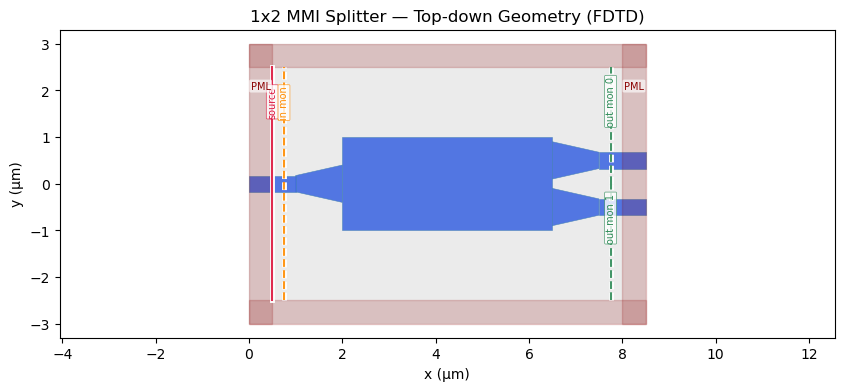

In [5]:
# 3. Geometry plot
plot_fdtd_geometry(
    mmi, solver=solver,
    title="1x2 MMI Splitter — Top-down Geometry (FDTD)",
)
plt.show()

In [ ]:
# 4. Wavelength sweep
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)  # um, O-band

print(f"Sweeping {len(wavelengths)} wavelengths: "
      f"{wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um")
print("(single broadband pulse; DFT monitors extract all wavelengths in one sim)")

# Source from top input port; measure coupling to each mode at output monitor
smat = solver.solve(mmi, wavelengths, port="top", input_mode=1)
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength

Sweeping 11 wavelengths: 1.260 - 1.360 um
(single broadband pulse; DFT monitors extract all wavelengths in one sim)
Using MPI version 4.1, 1 processes


In [ ]:
# 5. Print summary
wl_center = wavelengths[len(wavelengths) // 2]
idx = np.argmin(np.abs(wavelengths - wl_center))

# Power in fundamental mode at each output waveguide
# "out_0" / "out_1" match the order of output_monitor_centers: [+0.5, -0.5]
T_top = smat.transmission(port="out_0", in_mode=1, out_mode=1)  # [M]
T_bot = smat.transmission(port="out_1", in_mode=1, out_mode=1)  # [M]
T_total = T_top + T_bot  # insertion loss = sum of both outputs

print(f"\nResults at wavelength = {wl_center:.3f} um:")
print(f"  Top output power    : {T_top[idx]:.4f}")
print(f"  Bottom output power : {T_bot[idx]:.4f}")
print(f"  Total (sum)         : {T_total[idx]:.4f}")
print(f"  Insertion loss      : {10*np.log10(T_total[idx]):.2f} dB")
print(f"  (ideal 50/50 split -> T_each=0.5, IL_total=0.0 dB)")


Results at wavelength = 1.310 um:
  Top output power    : 0.4212
  Bottom output power : 0.4212
  Total (sum)         : 0.8423
  Insertion loss      : -0.75 dB
  (ideal 50/50 split -> T_each=0.5, IL_total=0.0 dB)


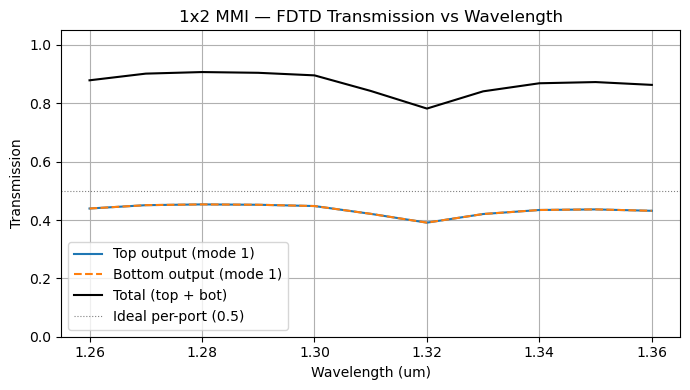

In [ ]:
# 6. Transmission vs wavelength: both outputs + total
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wavelengths, T_top,   label="Top output (mode 1)")
ax.plot(wavelengths, T_bot,   label="Bottom output (mode 1)", linestyle="--")
ax.plot(wavelengths, T_total, label="Total (top + bot)", color="k", lw=1.5)
ax.axhline(0.5, color="gray", linestyle=":", lw=0.8, label="Ideal per-port (0.5)")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("1x2 MMI — FDTD Transmission vs Wavelength")
ax.legend()
ax.grid(True)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()